# ITELv5 - SECCIÓN 5: EXTRACCIÓN Y CACHEO DE EMBEDDINGS (HuBERT)

En esta sección: (1) cargamos config; (2) extraemos embeddings HuBERT con enriquecimiento temporal; (3) guardamos y cacheamos los embeddings y su metadata.

Nota: El entrenamiento, evaluación y diagnósticos se realizarán en la siguiente sección (ITELv5_06), para mantener este notebook dedicado exclusivamente a la generación de embeddings.

🔍 Verificando estructura de carpetas...

✅ Estructura de carpetas completa.
🔧 Dependencias comprobadas.

📁 BASE_DIR: C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL
🖥️ GPU disponible: False
Rutas Principales de ITELv5:
Datos_Brutos:     C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Datos_Brutos
Datos Procesados: C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Datos_Procesados
Modelos:          C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Modelos
Reportes (CSV):   C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Reportes\CSV
Reportes (Figuras): C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Reportes\Figuras
Logs:             C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Logs
🔍 Carpeta Healthy con 308 subrutas de vocales
🔍 Carpeta Patients con 378 subrutas de vocales
✅ Configuración ITELv5 lista.
🔍 Verificando estructura de carpetas...

✅ Estructura de carpetas completa.
🔧 Dependencias comprobadas.

📁 BASE_DIR: C:\Users\USER\Documents\GitHub\ITEL-Tesis-

,categoria,subcarpeta,tipo,silabas,etiqueta,nombre,ruta
0,Healthy,01SAMOHL,vocal,NaN,a,4PK1A.wav,C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audi...
1,Healthy,01SAMOHL,vocal,NaN,e,4PK1E.wav,C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audi...
2,Healthy,01SAMOHL,vocal,NaN,i,4PK1I.wav,C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audi...
3,Healthy,01SAMOHL,vocal,NaN,o,4PK1O.wav,C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audi...
4,Healthy,01SAMOHL,vocal,NaN,u,4PK1U.wav,C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audi...



🎧 Iniciando preprocesamiento de audios...



Procesando: 100%|██████████| 3730/3730 [00:07<00:00, 466.77it/s] 


,categoria,subcarpeta,tipo,silabas,etiqueta,nombre,ruta,sr_final,estado,duracion_s
0,Healthy,01SAMOHL,vocal,NaN,a,4PK1A.wav,C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audi...,16000,OK,2.0
1,Healthy,01SAMOHL,vocal,NaN,e,4PK1E.wav,C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audi...,16000,OK,2.0
2,Healthy,01SAMOHL,vocal,NaN,i,4PK1I.wav,C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audi...,16000,OK,2.0
3,Healthy,01SAMOHL,vocal,NaN,o,4PK1O.wav,C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audi...,16000,OK,2.0
4,Healthy,01SAMOHL,vocal,NaN,u,4PK1U.wav,C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audi...,16000,OK,2.0



📊 Resumen de procesamiento:


estado
OK    3730
Name: count, dtype: int64


💾 Resumen exportado a: C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Reportes\CSV\preprocesamiento_resumen_v5.csv

🎙️ Ejemplo de preprocesamiento: C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Datos_Brutos\Healthy\H33\04_2SL\4TB4PAP.wav
💾 Gráfico de onda guardado en C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Reportes\Figuras\onda_preprocesamiento_v5.png


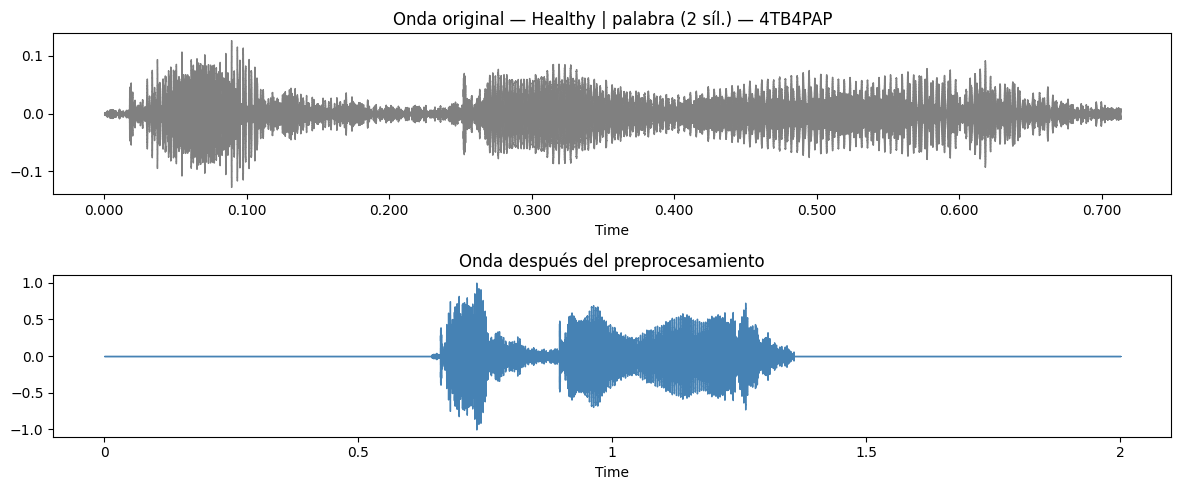


✅ Sección 4 (v5) completada. Listo para extracción de embeddings (Sección 5).


In [ ]:
# ===============================================================_
# ITELv5 - SECCIÓN 5: EXTRACCIÓN Y CACHEO DE EMBEDDINGS (HuBERT)
# ===============================================================_
%run "./ITELv5_01_CONFIGURACION.ipynb"
%run "./ITELv5_04_PREPROCESAMIENTO.ipynb"  # importa procesar_audio()

import torch, torchaudio, numpy as np, pandas as pd
from pathlib import Path
from tqdm import tqdm

In [2]:
# 5.1 - Carga de modelo HuBERT
bundle = torchaudio.pipelines.HUBERT_BASE
hubert_model = bundle.get_model()
hubert_model.eval()
print('✅ Modelo HuBERT cargado (solo extracción de embeddings).')

✅ Modelo HuBERT cargado (solo extracción de embeddings).


In [3]:
# 5.2 - Extracción de embeddings (4608 dims)
def extraer_embedding(ruta):
    y, sr, estado = procesar_audio(ruta)
    if y is None:
        return None
    y = y.astype(np.float32)
    wav_tensor = torch.tensor(y).unsqueeze(0)
    with torch.inference_mode():
        features, _ = hubert_model(wav_tensor)  # (1, T, 768)
    features = features.squeeze(0)  # (T, 768)
    T = features.shape[0]
    mean_emb = features.mean(dim=0)
    std_emb = features.std(dim=0)
    first_25 = features[: max(1, T//4) ].mean(dim=0)
    last_25  = features[- max(1, T//4) :].mean(dim=0)
    delta = first_25 - last_25
    slope_emb = torch.zeros(768)
    x = torch.arange(T, dtype=torch.float32)
    for dim in range(768):
        y_dim = features[:, dim]
        if torch.var(y_dim) == 0 or T < 2:
            slope_emb[dim] = 0
        else:
            slope_emb[dim] = torch.corrcoef(torch.stack([x, y_dim]))[0, 1]
    emb = torch.cat([mean_emb, std_emb, first_25, last_25, delta, slope_emb]).numpy()
    return emb

In [4]:
# 5.3 - Cargar listado de audios (desde gestión de contenido v5)

# Usa la nueva ruta ITELConfig.CSV_DIR
csv_path = ITELConfig.CSV_DIR / 'gestion_contenido_v5.csv'

if csv_path.exists():
    df_audios = pd.read_csv(csv_path)
else:
    raise FileNotFoundError(f'{csv_path} no existe. Ejecuta ITELv5_03_GESTION_CONTENIDO primero.')
print(f'✅ {len(df_audios)} audios listos para procesar.')
display(df_audios.head())

✅ 3730 audios listos para procesar.


,categoria,subcarpeta,tipo,silabas,etiqueta,nombre,ruta
0,Healthy,01SAMOHL,vocal,NaN,a,4PK1A.wav,C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audi...
1,Healthy,01SAMOHL,vocal,NaN,e,4PK1E.wav,C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audi...
2,Healthy,01SAMOHL,vocal,NaN,i,4PK1I.wav,C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audi...
3,Healthy,01SAMOHL,vocal,NaN,o,4PK1O.wav,C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audi...
4,Healthy,01SAMOHL,vocal,NaN,u,4PK1U.wav,C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audi...


In [5]:
# 5.4 - Extracción para todos los audios (o cargar si ya existen)

# Actualizado para usar la nueva carpeta PROCESADOS_DIR
emb_dir = ITELConfig.PROCESADOS_DIR 
npy_file = emb_dir / 'embeddings_v5.npy'
info_file = emb_dir / 'embeddings_info_v5.csv'

if npy_file.exists() and info_file.exists():
    X = np.load(npy_file)
    info = pd.read_csv(info_file)
    print('📄 Cargando embeddings existentes de disco.')
else:
    embeddings, meta = [], []
    print('\n🎧 Iniciando extracción de embeddings...\n')
    for _, row in tqdm(df_audios.iterrows(), total=len(df_audios), desc='Embeddings'):
        emb = extraer_embedding(row['ruta'])
        if emb is None:
            continue
        embeddings.append(emb)
        meta.append({
            'categoria': row.get('categoria'),
            'subcarpeta': row.get('subcarpeta'),
            'tipo': row.get('tipo'),
            'silabas': row.get('silabas'),
            'etiqueta': row.get('etiqueta'),
            'nombre': row.get('nombre')
        })
    X = np.stack(embeddings)
    info = pd.DataFrame(meta)
    
    # La carpeta ya debe existir (verificada por 01_CONFIGURACION)
    # emb_dir.mkdir(parents=True, exist_ok=True) # <- Línea eliminada
    
    np.save(npy_file, X)
    info.to_csv(info_file, index=False)
    print(f'💾 Guardado: {npy_file} y {info_file}')

print('Shape X:', X.shape)
display(info.head())

📄 Cargando embeddings existentes de disco.
Shape X: (3730, 4608)


,categoria,subcarpeta,tipo,silabas,etiqueta,nombre
0,Healthy,01SAMOHL,vocal,NaN,a,4PK1A.wav
1,Healthy,01SAMOHL,vocal,NaN,e,4PK1E.wav
2,Healthy,01SAMOHL,vocal,NaN,i,4PK1I.wav
3,Healthy,01SAMOHL,vocal,NaN,o,4PK1O.wav
4,Healthy,01SAMOHL,vocal,NaN,u,4PK1U.wav


In [6]:
# 5.5 - Resumen y verificación de cacheo
print('✅ Embeddings generados/cargados correctamente')
print(' - Shape X:', X.shape)
print(' - Registros info:', len(info))
print(' - Rutas de cache:')
print('    *', npy_file)
print('    *', info_file)

# Muestra rápida de metadata
try:
    display(info.head())
except Exception:
    print(info.head())

✅ Embeddings generados/cargados correctamente
 - Shape X: (3730, 4608)
 - Registros info: 3730
 - Rutas de cache:
    * C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Datos_Procesados\embeddings_v5.npy
    * C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Datos_Procesados\embeddings_info_v5.csv


,categoria,subcarpeta,tipo,silabas,etiqueta,nombre
0,Healthy,01SAMOHL,vocal,NaN,a,4PK1A.wav
1,Healthy,01SAMOHL,vocal,NaN,e,4PK1E.wav
2,Healthy,01SAMOHL,vocal,NaN,i,4PK1I.wav
3,Healthy,01SAMOHL,vocal,NaN,o,4PK1O.wav
4,Healthy,01SAMOHL,vocal,NaN,u,4PK1U.wav
